In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import linregress, theilslopes, kendalltau
plt.rcParams["figure.figsize"] = (12, 6)
sns.set_theme(style="whitegrid")

In [3]:
df_clean = pd.read_csv("final data.csv")
df_clean.head()

,YEAR,LAT,LON,MONTH,PRECIPITATION,Region,SEASON,TEMPRETURE
0,2001,22.0,25.000,JAN,0.0,West,Winter,11.85
1,2001,22.0,25.625,JAN,0.0,West,Winter,10.89
2,2001,22.0,26.250,JAN,0.0,West,Winter,11.20
3,2001,22.0,26.875,JAN,0.0,West,Winter,11.72
4,2001,22.0,27.500,JAN,0.0,West,Winter,12.49


In [4]:
df_clean[["TEMPRETURE", "PRECIPITATION"]].describe()

,TEMPRETURE,PRECIPITATION
count,126000.000000,126000.000000
mean,21.863194,3.401091
std,6.746927,14.105477
min,6.200000,0.000000
25%,15.820000,0.000000
50%,22.490000,0.010000
75%,27.920000,0.790000
max,36.280000,592.580000


In [5]:
annual_analysis = (
    df_clean.groupby("YEAR")
    .agg(
        MEAN_TEMPERATURE=("TEMPRETURE", "mean"),
        MEAN_PRECIPITATION=("PRECIPITATION", "mean")
    )
    .reset_index()
)
annual_analysis.head()

,YEAR,MEAN_TEMPERATURE,MEAN_PRECIPITATION
0,2001,21.630417,2.014845
1,2002,21.727139,2.508679
2,2003,21.666202,2.667369
3,2004,21.699512,2.439754
4,2005,21.656333,2.335012


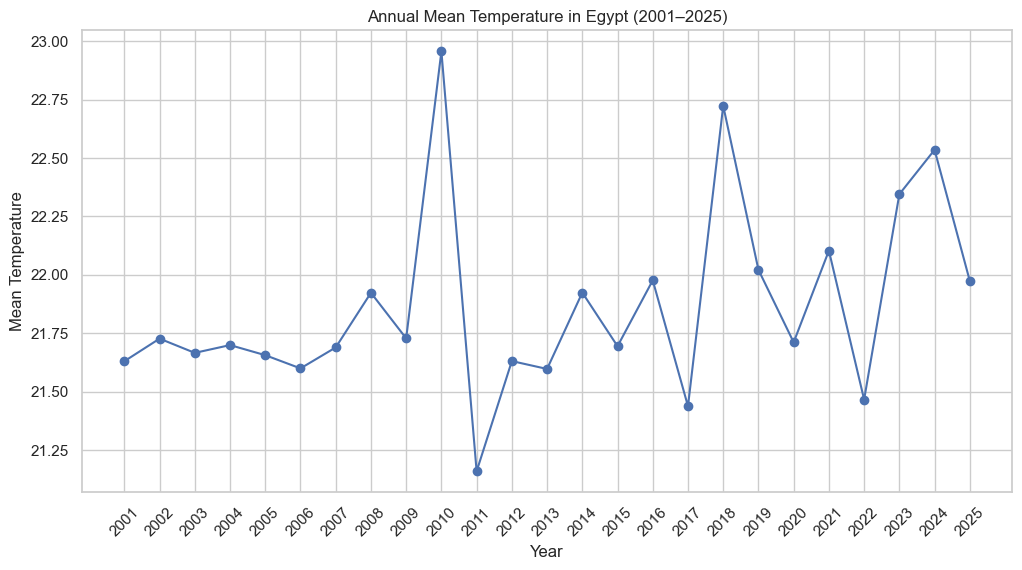

In [6]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_analysis["YEAR"],
    annual_analysis["MEAN_TEMPERATURE"],
    marker="o"
)
plt.title("Annual Mean Temperature in Egypt (2001–2025)")
plt.xlabel("Year")
plt.ylabel("Mean Temperature")
plt.xticks(annual_analysis["YEAR"], rotation=45)
plt.grid(True)
plt.show()

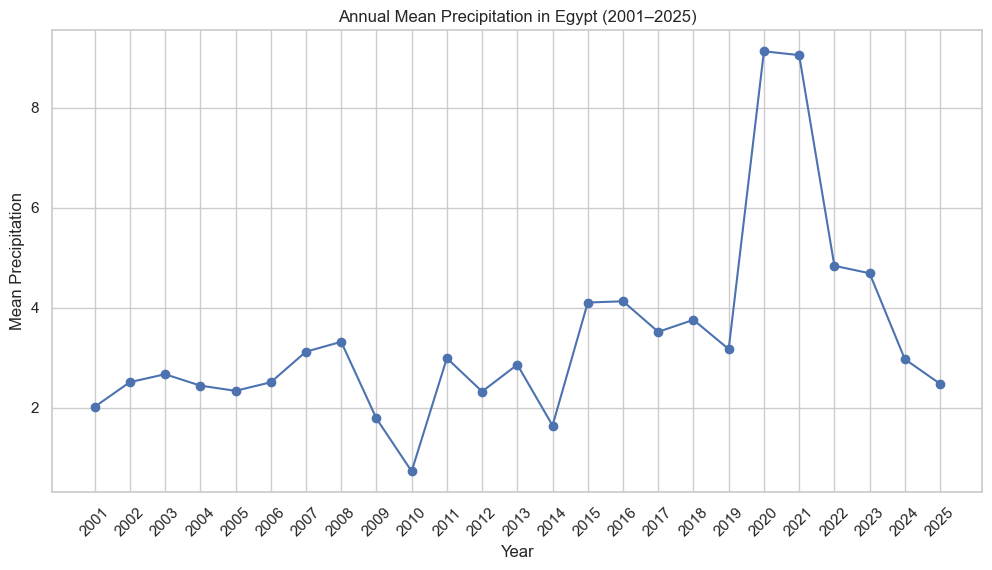

In [7]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_analysis["YEAR"],
    annual_analysis["MEAN_PRECIPITATION"],
    marker="o"
)
plt.title("Annual Mean Precipitation in Egypt (2001–2025)")
plt.xlabel("Year")
plt.ylabel("Mean Precipitation")
plt.xticks(annual_analysis["YEAR"], rotation=45)
plt.grid(True)
plt.show()

In [8]:
def analyze_trend(data, value_column):

    x = data["YEAR"]
    y = data[value_column]

    regression = linregress(x, y)
    kendall = kendalltau(x, y)
    sen = theilslopes(y, x, alpha=0.95)

    if regression.slope > 0:
        direction = "Increasing"
    elif regression.slope < 0:
        direction = "Decreasing"
    else:
        direction = "No Linear Change"

    return {
        "Variable": value_column,
        "Direction": direction,
        "Linear Slope Per Year": regression.slope,
        "Linear Change Per Decade": regression.slope * 10,
        "R Squared": regression.rvalue ** 2,
        "Linear Regression P-value": regression.pvalue,
        "Kendall Tau": kendall.statistic,
        "Kendall P-value": kendall.pvalue,
        "Sen Slope Per Year": sen.slope,
        "Sen Lower CI": sen.low_slope,
        "Sen Upper CI": sen.high_slope
    }

In [9]:
temperature_trend = analyze_trend(
    annual_analysis,
    "MEAN_TEMPERATURE"
)

precipitation_trend = analyze_trend(
    annual_analysis,
    "MEAN_PRECIPITATION"
)

trend_results = pd.DataFrame([
    temperature_trend,
    precipitation_trend
])

trend_results

,Variable,Direction,Linear Slope Per Year,Linear Change Per Decade,R Squared,Linear Regression P-value,Kendall Tau,Kendall P-value,Sen Slope Per Year,Sen Lower CI,Sen Upper CI
0,MEAN_TEMPERATURE,Increasing,0.019477,0.194766,0.121945,0.087084,0.28,0.051858,0.017858,-0.000298,0.033536
1,MEAN_PRECIPITATION,Increasing,0.133501,1.335011,0.253763,0.010248,0.38,0.007345,0.098279,0.027870,0.149006


In [10]:
for _, row in trend_results.iterrows():

    print("\nVariable:", row["Variable"])
    print("Direction:", row["Direction"])
    print("Change per decade:", row["Linear Change Per Decade"])
    print("P-value:", row["Linear Regression P-value"])

    if row["Linear Regression P-value"] < 0.05:
        print("Statistically significant linear trend")
    else:
        print("No statistically significant linear trend")


Variable: MEAN_TEMPERATURE
Direction: Increasing
Change per decade: 0.1947664529914531
P-value: 0.08708397580334488
No statistically significant linear trend

Variable: MEAN_PRECIPITATION
Direction: Increasing
Change per decade: 1.3350108058608057
P-value: 0.010248408203011386
Statistically significant linear trend


In [11]:
month_order = [
    "JAN", "FEB", "MAR", "APR",
    "MAY", "JUN", "JUL", "AUG",
    "SEP", "OCT", "NOV", "DEC"
]

monthly_analysis = (
    df_clean.groupby("MONTH")
    .agg(
        MEAN_TEMPERATURE=("TEMPRETURE", "mean"),
        MEAN_PRECIPITATION=("PRECIPITATION", "mean")
    )
    .reset_index()
)

monthly_analysis["MONTH"] = pd.Categorical(
    monthly_analysis["MONTH"],
    categories=month_order,
    ordered=True
)

monthly_analysis = monthly_analysis.sort_values("MONTH")

monthly_analysis

,MONTH,MEAN_TEMPERATURE,MEAN_PRECIPITATION
4,JAN,12.090490,9.203495
3,FEB,13.634890,6.652198
7,MAR,17.380886,5.683274
0,APR,21.731659,1.644651
8,MAY,25.848476,0.669632
6,JUN,28.718230,0.187600
5,JUL,29.841674,0.164804
1,AUG,30.138945,0.269800
11,SEP,27.682400,0.386949
10,OCT,23.483691,1.846930


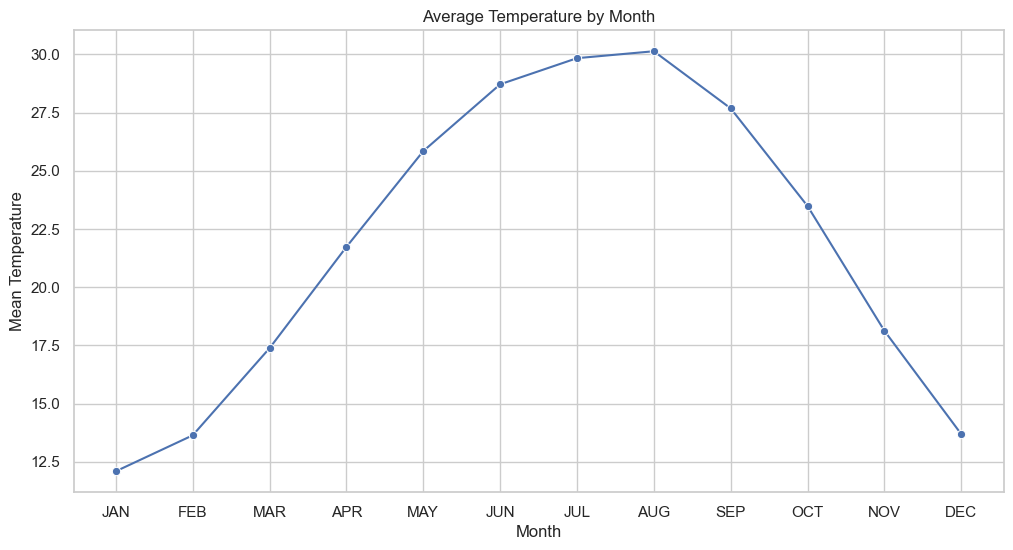

In [12]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_analysis,
    x="MONTH",
    y="MEAN_TEMPERATURE",
    marker="o"
)
plt.title("Average Temperature by Month")
plt.xlabel("Month")
plt.ylabel("Mean Temperature")
plt.show()

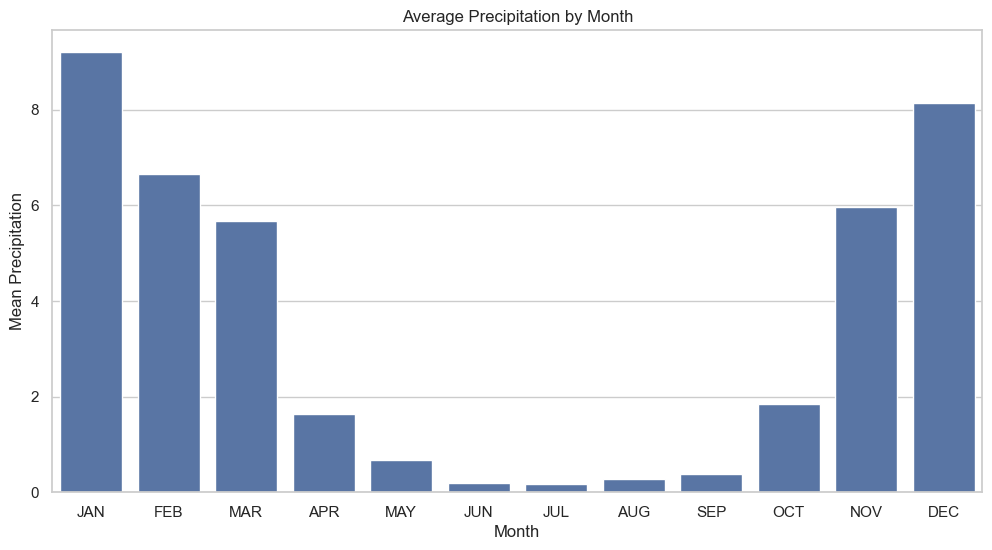

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=monthly_analysis,
    x="MONTH",
    y="MEAN_PRECIPITATION"
)
plt.title("Average Precipitation by Month")
plt.xlabel("Month")
plt.ylabel("Mean Precipitation")
plt.show()

In [14]:
season_order = ["Winter", "Spring", "Summer", "Autumn"]
seasonal_analysis = (
    df_clean.groupby("SEASON")
    .agg(
        MEAN_TEMPERATURE=("TEMPRETURE", "mean"),
        MEAN_PRECIPITATION=("PRECIPITATION", "mean")
    )
    .reset_index()
)
seasonal_analysis["SEASON"] = pd.Categorical(
    seasonal_analysis["SEASON"],
    categories=season_order,
    ordered=True
)
seasonal_analysis = seasonal_analysis.sort_values("SEASON")
seasonal_analysis

,SEASON,MEAN_TEMPERATURE,MEAN_PRECIPITATION
3,Winter,13.136156,7.998421
1,Spring,21.653674,2.665853
2,Summer,29.566283,0.207401
0,Autumn,23.096663,2.732691


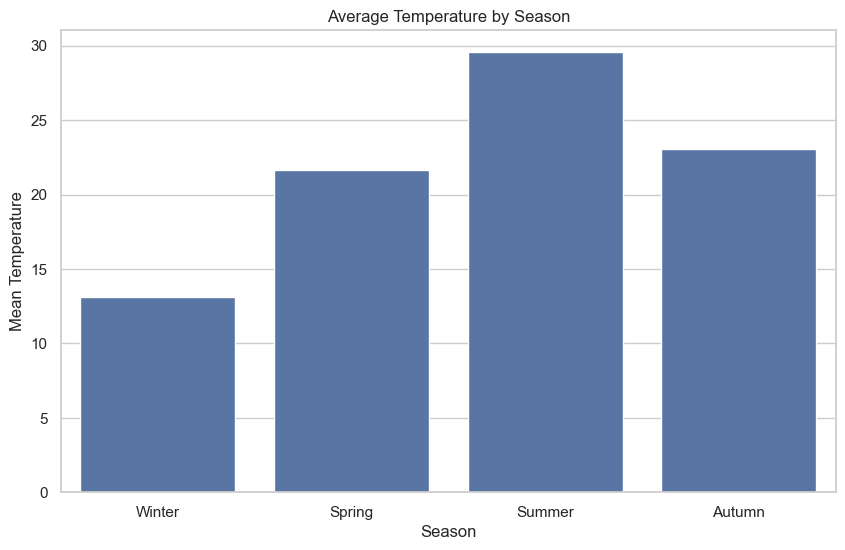

In [15]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=seasonal_analysis,
    x="SEASON",
    y="MEAN_TEMPERATURE"
)

plt.title("Average Temperature by Season")
plt.xlabel("Season")
plt.ylabel("Mean Temperature")
plt.show()

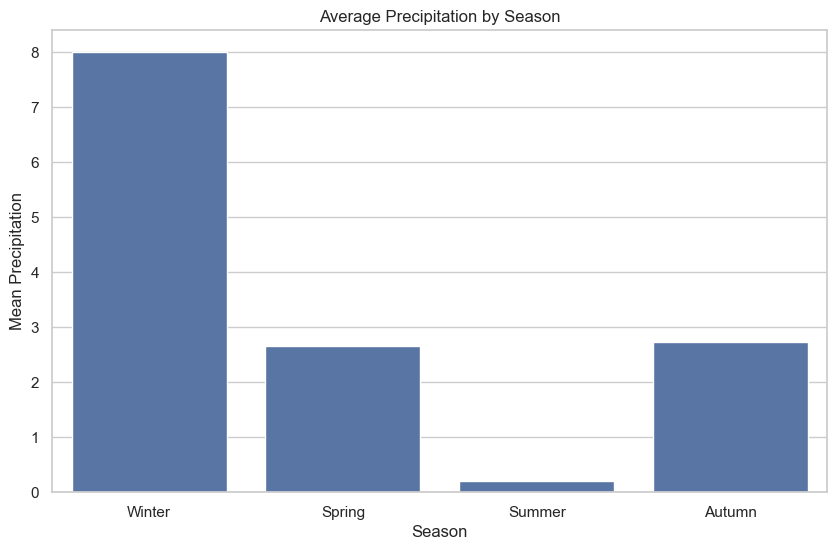

In [16]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=seasonal_analysis,
    x="SEASON",
    y="MEAN_PRECIPITATION"
)
plt.title("Average Precipitation by Season")
plt.xlabel("Season")
plt.ylabel("Mean Precipitation")
plt.show()

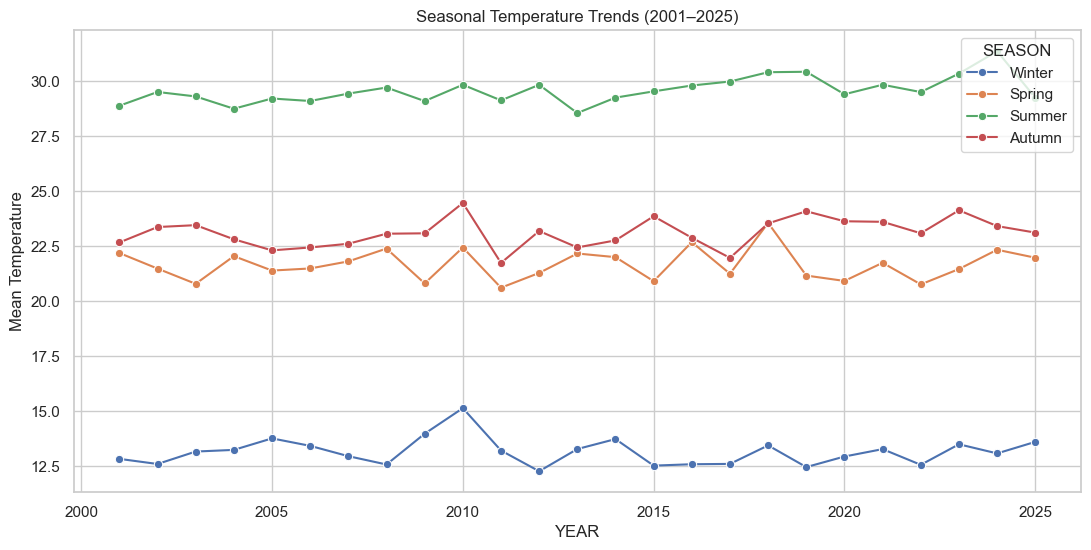

In [17]:
seasonal_trends = (
    df_clean.groupby(["YEAR", "SEASON"])
    .agg(
        MEAN_TEMPERATURE=("TEMPRETURE", "mean"),
        MEAN_PRECIPITATION=("PRECIPITATION", "mean")
    )
    .reset_index()
)
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=seasonal_trends,
    x="YEAR",
    y="MEAN_TEMPERATURE",
    hue="SEASON",
    hue_order=season_order,
    marker="o"
)
plt.title("Seasonal Temperature Trends (2001–2025)")
plt.ylabel("Mean Temperature")
plt.show()

In [18]:
climate_annual = annual_analysis[
    ["YEAR", "MEAN_TEMPERATURE", "MEAN_PRECIPITATION"]
].dropna()

climate_annual.head()

,YEAR,MEAN_TEMPERATURE,MEAN_PRECIPITATION
0,2001,21.159385,0.726234
1,2002,21.437996,1.641710
2,2003,21.466353,1.782151
3,2004,21.597369,2.014845
4,2005,21.599813,2.321413


In [19]:
pearson_result = stats.pearsonr(
    climate_annual["MEAN_TEMPERATURE"],
    climate_annual["MEAN_PRECIPITATION"]
)

spearman_result = stats.spearmanr(
    climate_annual["MEAN_TEMPERATURE"],
    climate_annual["MEAN_PRECIPITATION"]
)

print("Pearson Correlation:", pearson_result.statistic)
print("Pearson P-value:", pearson_result.pvalue)

print("\nSpearman Correlation:", spearman_result.statistic)
print("Spearman P-value:", spearman_result.pvalue)

Pearson Correlation: 0.9529514402787982
Pearson P-value: 2.0548444995948602e-13

Spearman Correlation: 1.0
Spearman P-value: 0.0


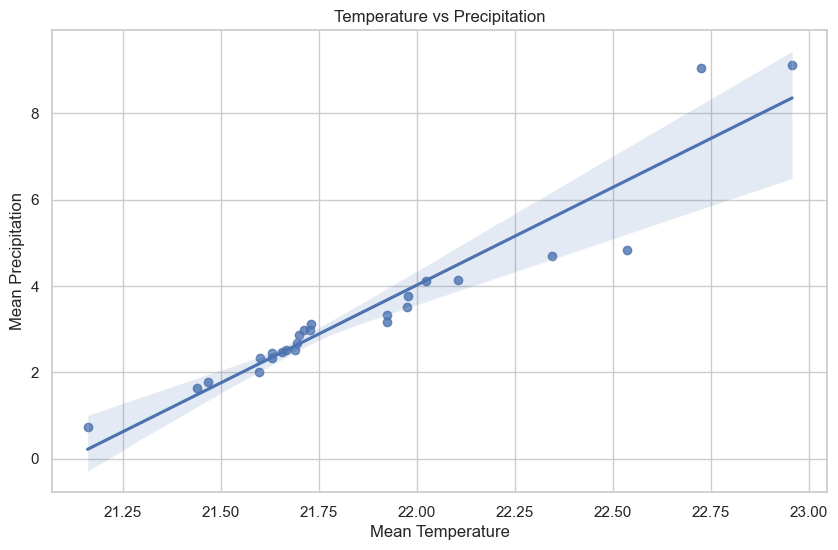

In [20]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=climate_annual,
    x="MEAN_TEMPERATURE",
    y="MEAN_PRECIPITATION"
)

plt.title("Temperature vs Precipitation")
plt.xlabel("Mean Temperature")
plt.ylabel("Mean Precipitation")
plt.show()

In [21]:
location_annual = (
    df_clean.groupby(["LAT", "LON", "YEAR"])
    .agg(
        MEAN_TEMPERATURE=("TEMPRETURE", "mean"),
        MEAN_PRECIPITATION=("PRECIPITATION", "mean")
    )
    .reset_index()
)

location_annual.head()

,LAT,LON,YEAR,MEAN_TEMPERATURE,MEAN_PRECIPITATION
0,22.0,25.0,2001,22.477500,0.000000
1,22.0,25.0,2002,22.811667,0.012500
2,22.0,25.0,2003,22.931667,0.150000
3,22.0,25.0,2004,22.833333,0.000000
4,22.0,25.0,2005,23.206667,0.400833


In [22]:
spatial_results = []

for (lat, lon), group in location_annual.groupby(["LAT", "LON"]):

    group = group.sort_values("YEAR")

    if len(group) < 10:
        continue

    temp_slope = theilslopes(
        group["MEAN_TEMPERATURE"],
        group["YEAR"]
    )

    rain_slope = theilslopes(
        group["MEAN_PRECIPITATION"],
        group["YEAR"]
    )

    temp_kendall = kendalltau(
        group["YEAR"],
        group["MEAN_TEMPERATURE"]
    )

    rain_kendall = kendalltau(
        group["YEAR"],
        group["MEAN_PRECIPITATION"]
    )

    spatial_results.append({
        "LAT": lat,
        "LON": lon,
        "TEMP_SEN_SLOPE": temp_slope.slope,
        "TEMP_KENDALL_TAU": temp_kendall.statistic,
        "TEMP_P_VALUE": temp_kendall.pvalue,
        "RAIN_SEN_SLOPE": rain_slope.slope,
        "RAIN_KENDALL_TAU": rain_kendall.statistic,
        "RAIN_P_VALUE": rain_kendall.pvalue
    })

spatial_results = pd.DataFrame(spatial_results)

spatial_results.head()

,LAT,LON,TEMP_SEN_SLOPE,TEMP_KENDALL_TAU,TEMP_P_VALUE,RAIN_SEN_SLOPE,RAIN_KENDALL_TAU,RAIN_P_VALUE
0,22.0,25.000,0.003299,0.998332,2.847732e-12,0.008462,0.998332,2.847732e-12
1,22.0,25.625,0.008079,1.000000,1.289390e-25,0.002067,0.998332,2.847732e-12
2,22.0,26.250,0.010046,0.998332,2.847732e-12,0.004546,0.998332,2.847732e-12
3,22.0,26.875,0.011450,1.000000,1.289390e-25,0.008916,1.000000,1.289390e-25
4,22.0,27.500,0.012396,1.000000,1.289390e-25,0.004446,0.998332,2.847732e-12


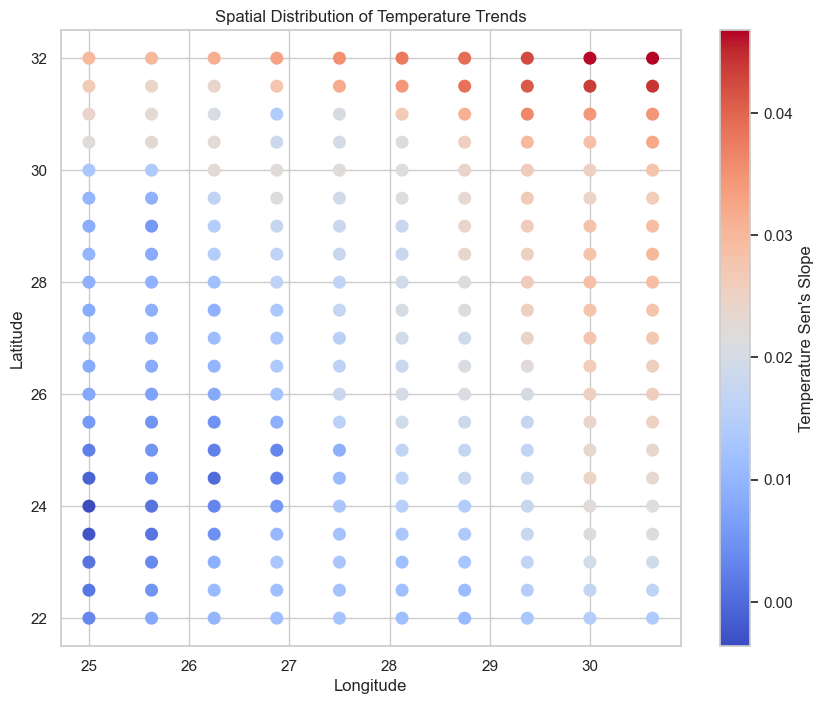

In [23]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    spatial_results["LON"],
    spatial_results["LAT"],
    c=spatial_results["TEMP_SEN_SLOPE"],
    cmap="coolwarm",
    s=70
)

plt.colorbar(scatter, label="Temperature Sen's Slope")
plt.title("Spatial Distribution of Temperature Trends")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

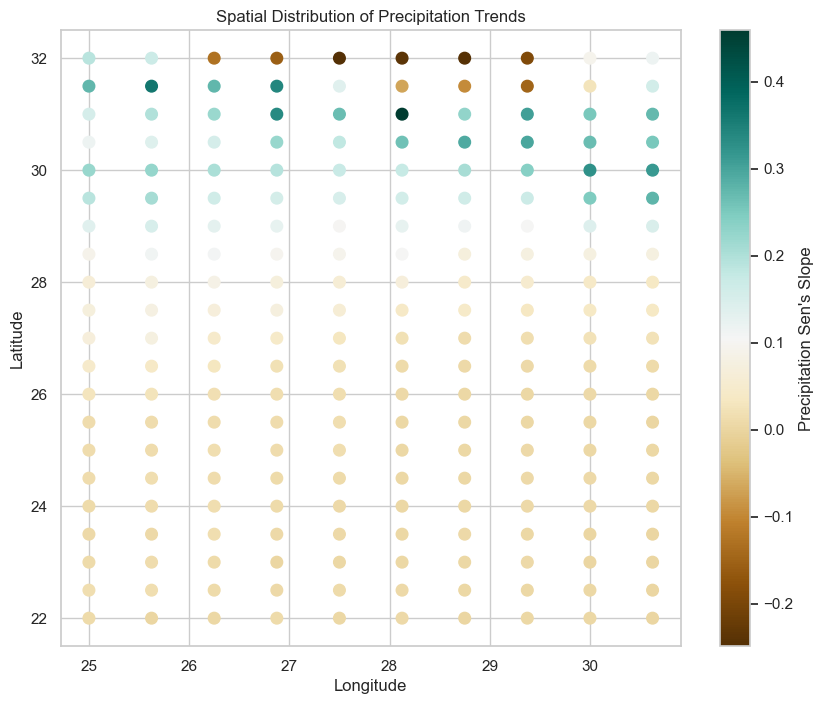

In [24]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    spatial_results["LON"],
    spatial_results["LAT"],
    c=spatial_results["RAIN_SEN_SLOPE"],
    cmap="BrBG",
    s=70
)

plt.colorbar(scatter, label="Precipitation Sen's Slope")
plt.title("Spatial Distribution of Precipitation Trends")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [25]:
print(
    "Significant Temperature Trends:",
    (spatial_results["TEMP_P_VALUE"] < 0.05).sum()
)

print(
    "Significant Precipitation Trends:",
    (spatial_results["RAIN_P_VALUE"] < 0.05).sum()
)

print("Total Locations:", len(spatial_results))

Significant Temperature Trends: 210
Significant Precipitation Trends: 210
Total Locations: 210
